# Did the phase boundaries move?

**The question, given the exploration.** Every phase-conditioned number in this project uses a fixed grid: powerplay overs 1 to 6, middle 7 to 15, death 16 to 20. The exploration showed the death overs getting more explosive and the powerplay surging. If teams now start the death assault at over 14, or treat the powerplay as running to over 8, then a fixed grid measures different things in the two seasons and the phase contrasts are confounded. This notebook asks whether the natural over-by-over boundaries in the data moved between seasons.

**What this notebook does.**
1. Builds an over profile per season (run rate, boundary rate, dot rate, wicket rate, pace share for each of the 20 overs) on first innings with a full allowance; a chase censors the death overs at the target, so second innings are shown descriptively only.
2. Detects *breaks*, overs where the trend changes, with a detector that treats the death ramp as a ramp: within a segment each channel is fitted as a straight line in the over index, and a break is a change of slope. A constant-level detector would place a break wherever a ramp crosses a level, which moves with how high the ramp goes, not where it starts.
3. Chooses the detector's penalty once on the pooled batting matrix, holds it fixed, and reports breaks per channel as the primary result.
4. Tests stability with a match cluster bootstrap and applies a pre-stated *move rule*: a boundary has moved if, on paired resamples, the two seasons' break locations differ by at least one over in at least 90% of them. Otherwise it is "not contradicted", never "validated".
5. Calibrates the rule on a synthetic season with a planted move, so the detector's resolution is stated rather than assumed.
6. Follows up the two loose ends the main run left: whether the alternative cost's verdicts can be read at all, and whether the one channel with a diffuse powerplay edge shows a real change.

**How to read this notebook.** A *break* is an over at which a new segment starts; an *anchor* is the full-data break nearest a grid edge (7 or 16). The *no-move plant* in the resolution section is the reference for reading any probability here: break locations jitter between resamples even when nothing changed, so a probability must be read against that band, not against 0.90 alone.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Resample counts come from `[phase_boundaries]`. Code lives in `scripts/phase_boundaries/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from common import derived_columns as dc
from mean_level_and_tail import season_contrast_bootstrap as scb
from phase_boundaries import phase_breaks as pb
from phase_boundaries.over_profiles import (CLEAN_FEATURES, BATTING_FEATURES, DEPLOYMENT_FEATURES,
                                            TAGGED_FEATURES, FIXED_BATTING_WEIGHTS, BreakFeatureTransform)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "phase_boundaries"
SEED = settings.seed(ANALYSIS)
CFG = settings.section("phase_boundaries")
PRODUCER = "phase_boundaries.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={CFG['n_resamples']}  robustness={CFG['robustness_resamples']}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  robustness=2000


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  seasons={sorted(df['year'].unique())}")
EXTRA = {"phase_boundaries": CFG, "fixture": USING_FIXTURE, "fixed_batting_weights": FIXED_BATTING_WEIGHTS}

rows=34,967  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Measurement-stability reads

Over numbers run 1 to 20, the mixed or unknown bowler kind is a small mass in both seasons (0.30% and 0.04%), extras are populated, and only a handful of legal balls lack a control tag. None of these can shift a boundary.

In [3]:
print("over_num range:", (int(df["over_num"].min()), int(df["over_num"].max())))
print("bowl_kind mixture/unknown mass by season:")
for year, vc in df.groupby("year")["bowl_kind"].value_counts().groupby(level=0):
    v = vc.droplevel(0)
    unk = v[[k for k in v.index if "pace" not in str(k) and "spin" not in str(k)]].sum()
    print(f"  {year}: {unk / v.sum():.4%}")
print(f"byes mean {df['byes'].mean():.4f}, legbyes mean {df['legbyes'].mean():.4f}")
n_legal_untagged = int((df["control_clean"].isna() & (pd.to_numeric(df["wide"]).fillna(0) == 0)).sum())
print(f"legal balls with untagged control_clean: {n_legal_untagged}")

over_num range: (1, 20)
bowl_kind mixture/unknown mass by season:
  2023: 0.3023%
  2024: 0.0351%
byes mean 0.0049, legbyes mean 0.0182
legal balls with untagged control_clean: 55


## Population and over profiles

The census table by season, then the first-innings profiles (batting channels, pace share, aggressive-shot share) and the second-innings profiles for the descriptive read. The pipeline below runs everything at once; it takes several minutes at the configured resample counts. Found: 74 and 70 first innings with a full allowance, none all out before the death.

In [4]:
run = pb.run_phase_boundaries(df, settings, SEED)
results_io.write_table(run["population"], settings, ANALYSIS, "population_counts", SEED, PRODUCER, EXTRA)
results_io.write_table(run["profiles"], settings, ANALYSIS, "over_profiles_first_innings", SEED, PRODUCER, EXTRA)
results_io.write_table(run["second_innings_profiles"], settings, ANALYSIS, "over_profiles_second_innings", SEED, PRODUCER, EXTRA)
display(run["population"])
show = ["year", "over_num", "n_legal", "n_faced"] + CLEAN_FEATURES + TAGGED_FEATURES
run["profiles"][show].round(3)

,year,dls_reduced,failed_chase,first_innings,successful_chase,first_innings_all_out_before_death
0,2023,2,40,74,31,0
1,2024,2,34,70,36,0


,year,over_num,n_legal,n_faced,run_rate,boundary_rate,dot_rate,wicket_rate,pace_share,aggressive_share
0,2023,1,444,444,5.622,0.140,0.574,0.020,0.959,0.032
1,2023,2,444,451,8.486,0.233,0.466,0.031,0.892,0.118
2,2023,3,444,445,8.405,0.231,0.463,0.043,0.905,0.137
3,2023,4,444,447,9.216,0.244,0.438,0.034,0.743,0.181
4,2023,5,444,448,9.432,0.257,0.391,0.047,0.716,0.185
5,2023,6,444,445,9.405,0.247,0.353,0.029,0.500,0.155
6,2023,7,444,445,7.189,0.121,0.319,0.036,0.230,0.121
7,2023,8,444,447,7.851,0.139,0.300,0.031,0.230,0.152
8,2023,9,444,446,8.014,0.143,0.283,0.040,0.203,0.164
9,2023,10,444,445,8.203,0.153,0.285,0.045,0.324,0.157


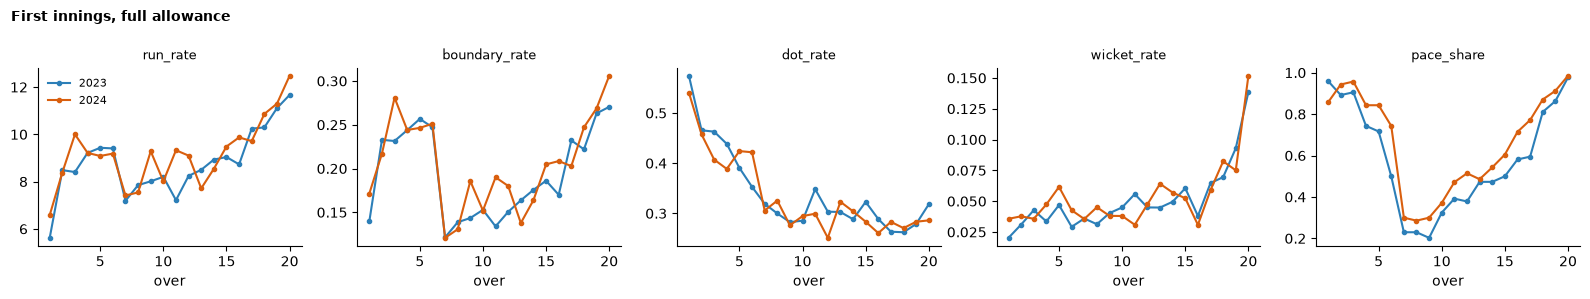

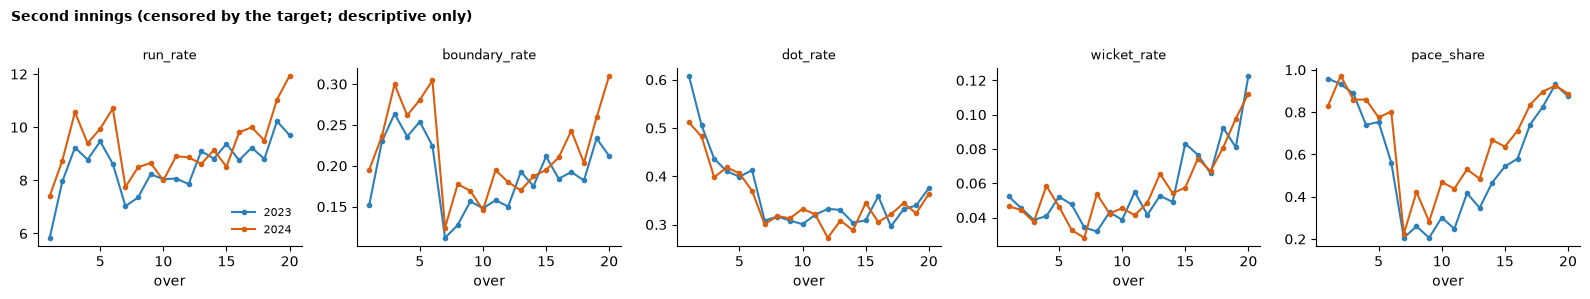

In [5]:
fig = pb.plot_channel_profiles(run["profiles"], BATTING_FEATURES + DEPLOYMENT_FEATURES, "First innings, full allowance")
results_io.write_figure(fig, settings, ANALYSIS, "profiles_first_innings", SEED, PRODUCER)
plt.show()
fig = pb.plot_channel_profiles(run["second_innings_profiles"], BATTING_FEATURES + DEPLOYMENT_FEATURES,
                               "Second innings (censored by the target; descriptive only)")
results_io.write_figure(fig, settings, ANALYSIS, "profiles_second_innings", SEED, PRODUCER)
plt.show()

## Choosing the penalty

The detector needs a penalty that says how much a break must improve the fit to be worth adding. It is scanned on the pooled full-data batting matrix and set once, at the log-midpoint of the widest run of values that yield two or three breaks in both seasons; the same value per unit of weighted cost is then used for every channel and every resample. The RBF cost (the robustness check below) gets its own scan.

In [6]:
for name, key in (("piecewise_linear", "penalty"), ("rbf", "rbf_penalty")):
    chosen = run[key]
    print(f"{name}: penalty={chosen['penalty']:.4f}  plateau={chosen.get('plateau')}  grid points={chosen.get('plateau_grid_points')}")
    results_io.write_table(chosen["scan"], settings, ANALYSIS, f"penalty_scan_{name}", SEED, PRODUCER,
                           {**EXTRA, "chosen_penalty": chosen["penalty"], "plateau": chosen.get("plateau")})
run["penalty"]["scan"][run["penalty"]["scan"]["qualifies"]].head(20)

piecewise_linear: penalty=3.2724  plateau=(2.3116553117338157, 4.632440713512769)  grid points=13
rbf: penalty=1.3333  plateau=(0.8148785550647237, 2.1815533830219107)  grid points=18


,penalty,breaks_2023,breaks_2024,qualifies
82,2.311655,2,3,True
83,2.449516,2,3,True
84,2.595599,2,3,True
85,2.750393,2,3,True
86,2.914419,2,3,True
87,3.088227,2,3,True
88,3.272401,2,2,True
89,3.467558,2,2,True
90,3.674354,2,2,True
91,3.893482,2,2,True


## Where the breaks fall on the full data

Break-start overs per channel and season (primary) and on the pooled batting matrix (descriptive), then the anchor for each named boundary. A blank anchor means that channel shows no slope change within three overs of that grid edge.

In [7]:
results_io.write_table(run["full_breaks"].assign(break_starts=run["full_breaks"]["break_starts"].astype(str)),
                       settings, ANALYSIS, "full_data_breaks", SEED, PRODUCER, EXTRA)
results_io.write_table(run["anchors"], settings, ANALYSIS, "boundary_anchors", SEED, PRODUCER, EXTRA)
display(run["full_breaks"])
run["anchors"].pivot_table(index=["kind", "channel", "boundary"], columns="year", values="anchor_over")

,year,channel,kind,break_starts
0,2023,run_rate,per_channel,"[7, 11]"
1,2023,boundary_rate,per_channel,[7]
2,2023,dot_rate,per_channel,[8]
3,2023,wicket_rate,per_channel,[18]
4,2023,pace_share,per_channel,[7]
5,2023,batting_matrix,pooled,"[7, 16]"
6,2024,run_rate,per_channel,"[4, 7, 13]"
7,2024,boundary_rate,per_channel,[7]
8,2024,dot_rate,per_channel,[7]
9,2024,wicket_rate,per_channel,[16]


year                                            2023  2024
kind        channel        boundary                       
per_channel boundary_rate  powerplay_to_middle   7.0   7.0
            dot_rate       powerplay_to_middle   8.0   7.0
            pace_share     powerplay_to_middle   7.0   7.0
            run_rate       middle_to_death       NaN  13.0
                           powerplay_to_middle   7.0   7.0
            wicket_rate    middle_to_death      18.0  16.0
pooled      batting_matrix middle_to_death      16.0  16.0
                           powerplay_to_middle   7.0   7.0

Every channel breaks at over 7 in both seasons: run rate, boundary rate, pace share and the pooled matrix exactly at 7, dot rate at 8 in 2023 and 7 in 2024. The powerplay edge is a crisp feature of the data. The death is different: run rate, boundary rate and dot rate show no slope change anywhere near over 16 in either season. Once the fielding restrictions lift, scoring climbs as one long ramp to the end, and a ramp is one segment to this detector. Only the wicket channel breaks late (18 in 2023, 16 in 2024), and the pooled matrix puts a descriptive break at 16 in both seasons, exactly the grid.

## Stability under resampling, and the move rule

Per channel and boundary: the modal break location and the share of resamples with no break near the anchor, per season; the share of resamples where both seasons had a location; the mean paired difference; P(|difference| ≥ 1 over) split by direction; the verdict. The histograms below show where each boundary landed across resamples.

In [8]:
move = run["move"]
results_io.write_table(move, settings, ANALYSIS, "move_test", SEED, PRODUCER, EXTRA)
results_io.write_table(run["histograms"], settings, ANALYSIS, "break_location_histograms", SEED, PRODUCER, EXTRA)
move.round(3)

,channel,boundary,kind,grid_edge,anchor_2023,anchor_2024,modal_over_2023,missing_share_2023,modal_over_2024,missing_share_2024,paired_share,mean_paired_difference,p_abs_difference_ge_1,p_later_earlier_by_ge_1,p_later_later_by_ge_1,verdict
0,run_rate,powerplay_to_middle,per_channel,7,7.0,7.0,7.0,0.002,7.0,0.008,0.991,0.116,0.623,0.272,0.351,not_contradicted
1,run_rate,middle_to_death,per_channel,16,NaN,13.0,NaN,1.000,13.0,0.173,0.000,NaN,NaN,NaN,NaN,not_anchored
2,boundary_rate,powerplay_to_middle,per_channel,7,7.0,7.0,7.0,0.000,7.0,0.002,0.998,0.007,0.057,0.028,0.029,not_contradicted
3,boundary_rate,middle_to_death,per_channel,16,NaN,NaN,NaN,1.000,NaN,1.000,0.000,NaN,NaN,NaN,NaN,not_anchored
4,dot_rate,powerplay_to_middle,per_channel,7,8.0,7.0,10.0,0.001,7.0,0.208,0.791,-1.743,0.877,0.710,0.167,not_contradicted
5,dot_rate,middle_to_death,per_channel,16,NaN,NaN,NaN,1.000,NaN,1.000,0.000,NaN,NaN,NaN,NaN,not_anchored
6,wicket_rate,powerplay_to_middle,per_channel,7,NaN,NaN,NaN,1.000,NaN,1.000,0.000,NaN,NaN,NaN,NaN,not_anchored
7,wicket_rate,middle_to_death,per_channel,16,18.0,16.0,18.0,0.010,16.0,0.000,0.990,-0.491,0.686,0.462,0.224,not_contradicted
8,pace_share,powerplay_to_middle,per_channel,7,7.0,7.0,7.0,0.000,7.0,0.000,1.000,-0.385,0.232,0.221,0.011,not_contradicted
9,pace_share,middle_to_death,per_channel,16,NaN,NaN,NaN,1.000,NaN,1.000,0.000,NaN,NaN,NaN,NaN,not_anchored


The powerplay edge does not move: boundary rate sits at 7 in 99.8% of resamples in both seasons with P(|difference| ≥ 1) of 0.06, pace share is at 7 in every resample, run rate 0.36. Dot rate is the one channel worth a second look: anchored at 8 in 2023 and 7 in 2024, modal location 10 against 7, P(|difference| ≥ 1) of 0.88 with most of the mass on "earlier in 2024". That is below the rule and, as the resolution section shows, only just above the band a detector produces when nothing moved; it reads as a diffuse 2023 edge rather than a move, and the follow-up at the end tests it directly. At the death, the wicket channel pairs at 0.69 and the pooled matrix at 0.71, both inside the no-move band. Verdicts: not contradicted everywhere the rule could be applied; not anchored for the three batting channels at the death, because there is no death break to test.

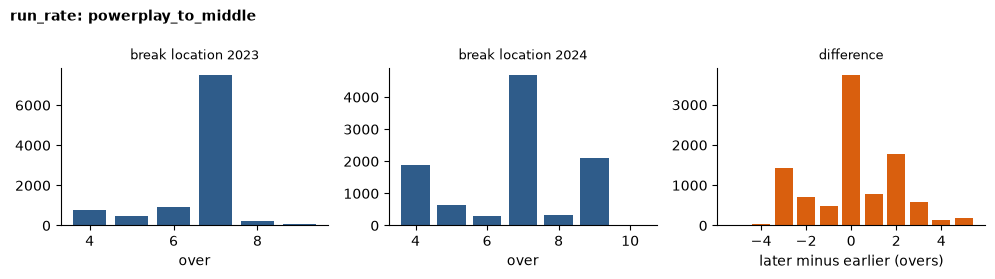

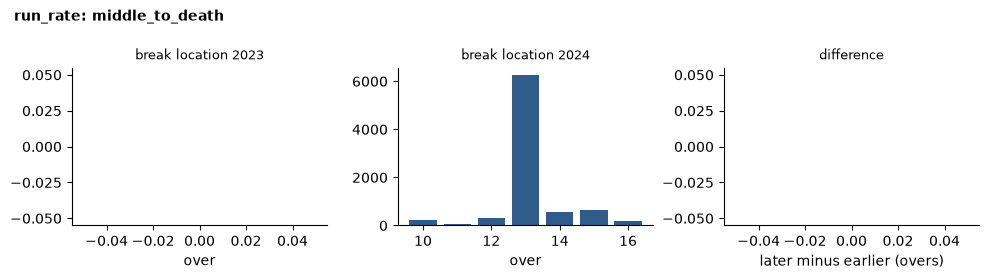

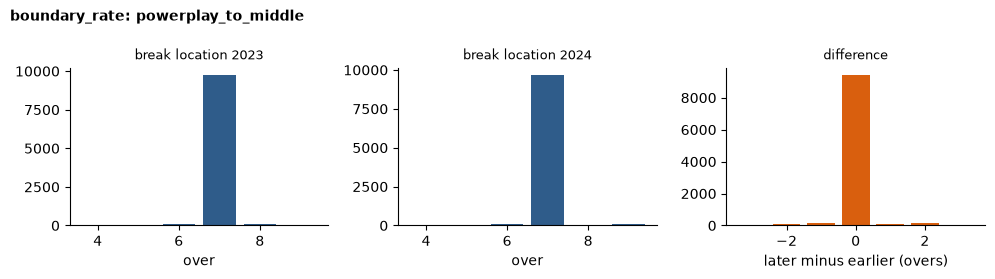

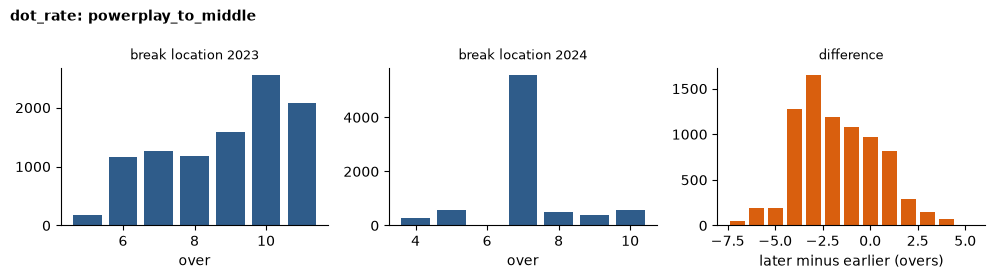

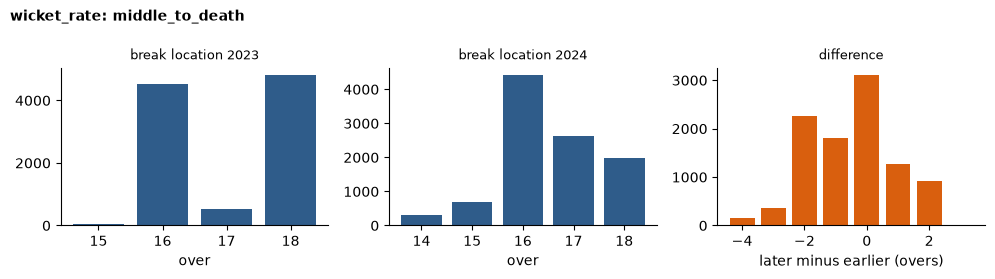

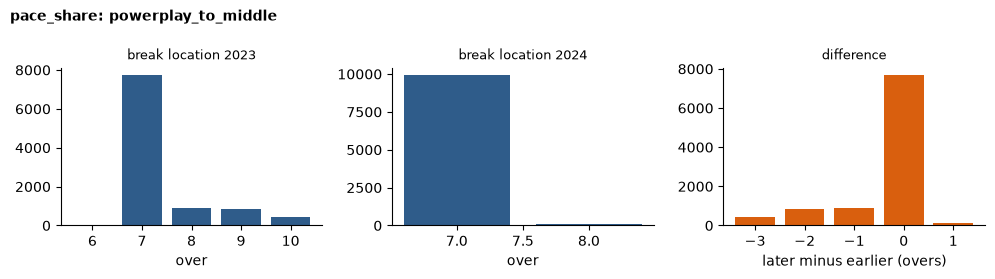

In [9]:
for channel in BATTING_FEATURES + DEPLOYMENT_FEATURES:
    for boundary in ("powerplay_to_middle", "middle_to_death"):
        sub = run["histograms"][(run["histograms"]["channel"] == channel) & (run["histograms"]["boundary"] == boundary)]
        if sub.empty:
            continue
        fig = pb.plot_break_histograms(run["histograms"], channel, boundary, YEARS)
        results_io.write_figure(fig, settings, ANALYSIS, f"break_histogram_{channel}_{boundary}", SEED, PRODUCER)
        plt.show()

## Robustness: a different cost

The same pipeline with an RBF cost, which reacts to a change in level rather than slope, and its own scanned penalty at a smaller resample count.

In [10]:
results_io.write_table(run["rbf_full_breaks"].assign(break_starts=run["rbf_full_breaks"]["break_starts"].astype(str)),
                       settings, ANALYSIS, "rbf_full_data_breaks", SEED, PRODUCER, EXTRA)
results_io.write_table(run["rbf_move"], settings, ANALYSIS, "rbf_move_test", SEED, PRODUCER, EXTRA)
run["rbf_move"][["channel", "boundary", "kind", f"anchor_{YEARS[0]}", f"anchor_{YEARS[1]}", f"modal_over_{YEARS[0]}",
                 f"modal_over_{YEARS[1]}", "paired_share", "mean_paired_difference", "p_abs_difference_ge_1", "verdict"]].round(3)

,channel,boundary,kind,anchor_2023,anchor_2024,modal_over_2023,modal_over_2024,paired_share,mean_paired_difference,p_abs_difference_ge_1,verdict
0,run_rate,powerplay_to_middle,per_channel,7.0,7.0,7,7,0.970,-0.266,0.356,not_contradicted
1,run_rate,middle_to_death,per_channel,17.0,15.0,17,15,1.000,-1.787,0.930,moved
2,boundary_rate,powerplay_to_middle,per_channel,7.0,7.0,7,7,1.000,-0.038,0.048,not_contradicted
3,boundary_rate,middle_to_death,per_channel,17.0,15.0,17,15,1.000,-1.718,0.936,moved
4,dot_rate,powerplay_to_middle,per_channel,8.0,7.0,8,7,1.000,-0.220,0.664,not_contradicted
5,dot_rate,middle_to_death,per_channel,16.0,15.0,16,16,0.522,-0.655,0.816,not_contradicted
6,wicket_rate,powerplay_to_middle,per_channel,10.0,7.0,10,7,0.862,-2.893,0.932,moved
7,wicket_rate,middle_to_death,per_channel,15.0,18.0,17,18,0.998,1.994,0.811,not_contradicted
8,pace_share,powerplay_to_middle,per_channel,7.0,7.0,7,7,1.000,0.144,0.151,not_contradicted
9,pace_share,middle_to_death,per_channel,18.0,15.0,18,15,1.000,-2.850,0.995,moved


RBF disagrees with the primary detector at the death: it finds breaks at 17 in 2023 and 15 in 2024 in run rate and boundary rate (P 0.93 and 0.94) and 18 to 15 in pace share (P 0.995), all "moved". Because RBF places a break where values cross into death-level territory, a higher or steeper 2024 death pulls that crossing earlier even if the ramp starts at the same over, so this is consistent with the death getting more explosive (which the season contrasts already show) and is not by itself evidence that the phase begins earlier. Whether its verdicts can be read at all is settled by the follow-up below.

## Resolution: what can this detector see?

The synthetic fixture with the death boundary planted at the same over in both seasons (no move), one over earlier in the later season, and two overs earlier. The rows per batting channel show what P(|difference| ≥ 1) the rule produces under each plant; the smallest plant on which a channel returns `moved` is the detector's resolution, and the no-move rows are the rule's false-fire level.

In [11]:
plants = {"no_move": {YEARS[0]: 16, YEARS[1]: 16},
          "one_over_earlier": {YEARS[0]: 16, YEARS[1]: 15},
          "two_overs_earlier": {YEARS[0]: 16, YEARS[1]: 14}}
resolution_rows = []
for name, edges in plants.items():
    table = pb.resolution_check(settings, SEED, int(CFG["resolution_check_resamples"]), edges)
    table.insert(0, "plant", name)
    resolution_rows.append(table)
resolution = pd.concat(resolution_rows, ignore_index=True)
results_io.write_table(resolution, settings, ANALYSIS, "resolution_check", SEED, PRODUCER, EXTRA)
batting = resolution[resolution["channel"].isin(BATTING_FEATURES)]
fires = batting[batting["verdict"] == "moved"].groupby("plant")["channel"].apply(list)
print("plants on which a batting channel returns moved:", dict(fires))
resolution[["plant", "channel", f"anchor_{YEARS[0]}", f"anchor_{YEARS[1]}", f"modal_over_{YEARS[0]}", f"modal_over_{YEARS[1]}",
            "paired_share", "mean_paired_difference", "p_abs_difference_ge_1", "verdict"]].round(3)

plants on which a batting channel returns moved: {'two_overs_earlier': ['boundary_rate', 'wicket_rate']}


,plant,channel,anchor_2023,anchor_2024,modal_over_2023,modal_over_2024,paired_share,mean_paired_difference,p_abs_difference_ge_1,verdict
0,no_move,run_rate,15.0,14.0,15.0,14.0,1.000,-0.678,0.667,not_contradicted
1,no_move,boundary_rate,15.0,15.0,15.0,15.0,0.975,-0.158,0.656,not_contradicted
2,no_move,dot_rate,14.0,15.0,13.0,15.0,0.994,0.521,0.716,not_contradicted
3,no_move,wicket_rate,14.0,16.0,14.0,16.0,0.932,1.886,0.871,not_contradicted
4,no_move,pace_share,NaN,16.0,NaN,16.0,0.000,NaN,NaN,not_anchored
5,no_move,batting_matrix,14.0,16.0,15.0,16.0,1.000,1.718,0.858,not_contradicted
6,one_over_earlier,run_rate,15.0,14.0,15.0,14.0,0.996,-1.013,0.752,not_contradicted
7,one_over_earlier,boundary_rate,15.0,14.0,15.0,14.0,0.994,-0.861,0.695,not_contradicted
8,one_over_earlier,dot_rate,15.0,14.0,15.0,14.0,0.913,-0.512,0.804,not_contradicted
9,one_over_earlier,wicket_rate,14.0,16.0,14.0,15.0,0.907,1.484,0.820,not_contradicted


With no move planted the batting channels still return P(|difference| ≥ 1) of 0.65 to 0.87, because break locations jitter by an over between resamples. A one-over plant gives 0.7 to 0.85, below the rule; a two-over plant fires on some channels. So on a 70-match season this detector resolves moves of about two overs, not one, and the real-data probabilities above have to be read against the 0.65 to 0.87 band. The grid statement that follows is "no batting-channel boundary moved by two or more overs; the powerplay edge is stable to within one over".

## Descriptive map

The 20 overs of each season plotted in the plane of the first two principal components of the weighted batting matrix, every over annotated, with the scree (how much variance each component carries). No test reads this figure; it shows the shape the detector was working on.

scree (explained variance ratio): [0.686 0.212 0.101 0.002]  cumulative PC1+PC2: 0.898


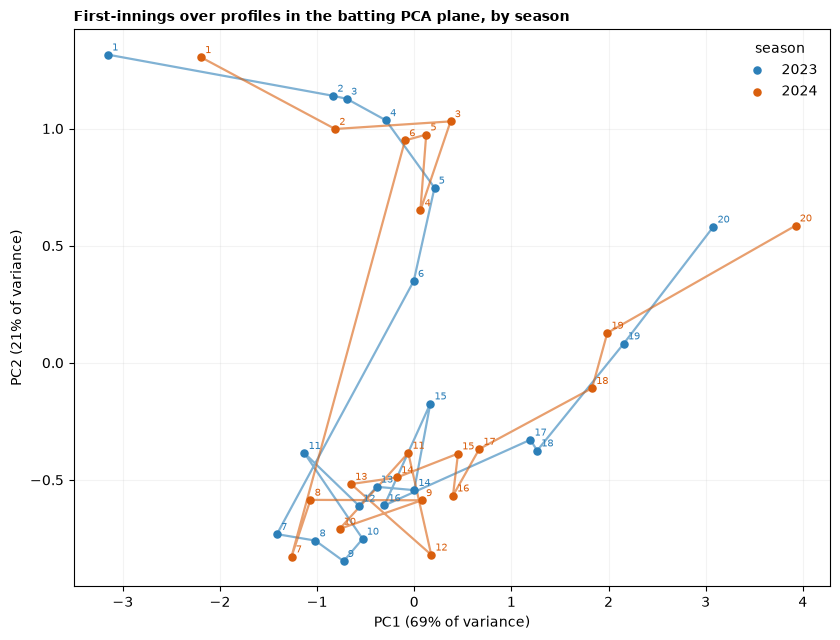

In [12]:
print("scree (explained variance ratio):", np.round(run["scree"], 3), " cumulative PC1+PC2:", round(float(run["scree"][:2].sum()), 3))
fig = pb.plot_trajectories(run["trajectory"])
results_io.write_figure(fig, settings, ANALYSIS, "batting_pca_trajectory", SEED, PRODUCER)
plt.show()

## Appendix: why pace share is its own channel

Reliability weights estimated from per-cell sampling variance on the five clean channels, uncapped and capped. Found: uncapped, pace share takes about 4.4 of the 5 units of weight, because its per-cell variance is smallest; a matrix weighted that way is a pace-deployment map with the batting channels along for the ride. That is why the batting matrix uses fixed weights and pace share is analysed alone.

In [13]:
weights = pd.DataFrame({
    "uncapped": BreakFeatureTransform(features=CLEAN_FEATURES).fit(run["profiles"]).weights_,
    "capped_2.0": BreakFeatureTransform(features=CLEAN_FEATURES, max_weight=2.0).fit(run["profiles"]).weights_,
}).rename_axis("feature").reset_index()
results_io.write_table(weights, settings, ANALYSIS, "appendix_inverse_variance_weights", SEED, PRODUCER, EXTRA)
weights.round(3)

,feature,uncapped,capped_2.0
0,run_rate,0.080,0.388
1,boundary_rate,0.248,1.206
2,dot_rate,0.237,1.153
3,wicket_rate,0.052,0.252
4,pace_share,4.383,2.000


## Follow-up: can the RBF verdicts be read?

The RBF cost is run through the same three plants so its "moved" verdicts on the real data can be compared with what it does when nothing moved.

In [14]:
from common.synthetic_ballframe import make_synthetic_ballframe

rbf_rows = []
for name, edges in plants.items():
    fixture = make_synthetic_ballframe(n_matches_per_season=70, death_edge_by_season=edges, seed=7)
    kept_fx, _ = pb.first_innings_full_allowance(fixture, settings)
    stats_fx = pb.precompute_match_over_stats(kept_fx)
    profiles_fx = pb.profiles_full(stats_fx)
    matrices_fx, _ = pb.batting_matrices(profiles_fx)
    pen_fx = pb.choose_penalty(matrices_fx, "rbf")
    breaks_fx = pb.full_data_breaks(profiles_fx, np.nan, "rbf", pen_fx["penalty"])
    stability_fx = pb.break_stability(stats_fx, pen_fx["penalty"], int(CFG["resolution_check_resamples"]), SEED, cost="rbf")
    table, _ = pb.move_test(stability_fx, pb.boundary_anchors(breaks_fx))
    table = table[table["boundary"] == "middle_to_death"].copy()
    table.insert(0, "plant", name)
    table["penalty"] = pen_fx["penalty"]
    rbf_rows.append(table)
rbf_resolution = pd.concat(rbf_rows, ignore_index=True)
results_io.write_table(rbf_resolution, settings, ANALYSIS, "rbf_resolution_check", SEED, PRODUCER, EXTRA)
fires = rbf_resolution[rbf_resolution["channel"].isin(BATTING_FEATURES) & (rbf_resolution["verdict"] == "moved")]
print("RBF: plants on which a batting channel returns moved:", dict(fires.groupby("plant")["channel"].apply(list)))
rbf_resolution[["plant", "channel", f"anchor_{YEARS[0]}", f"anchor_{YEARS[1]}", f"modal_over_{YEARS[0]}",
                f"modal_over_{YEARS[1]}", "paired_share", "mean_paired_difference", "p_abs_difference_ge_1", "verdict"]].round(3)

RBF: plants on which a batting channel returns moved: {'no_move': ['run_rate'], 'one_over_earlier': ['dot_rate'], 'two_overs_earlier': ['dot_rate']}


,plant,channel,anchor_2023,anchor_2024,modal_over_2023,modal_over_2024,paired_share,mean_paired_difference,p_abs_difference_ge_1,verdict
0,no_move,run_rate,15.0,17.0,15,18,1.000,2.352,0.988,moved
1,no_move,boundary_rate,15.0,15.0,15,15,1.000,-0.120,0.530,not_contradicted
2,no_move,dot_rate,16.0,15.0,16,15,1.000,-0.976,0.790,not_contradicted
3,no_move,wicket_rate,14.0,16.0,14,16,1.000,1.690,0.851,not_contradicted
4,no_move,pace_share,15.0,16.0,16,16,1.000,0.659,0.552,not_contradicted
5,no_move,batting_matrix,15.0,16.0,16,16,1.000,0.302,0.570,not_contradicted
6,one_over_earlier,run_rate,15.0,15.0,15,15,1.000,-0.525,0.553,not_contradicted
7,one_over_earlier,boundary_rate,15.0,15.0,15,15,1.000,-0.319,0.454,not_contradicted
8,one_over_earlier,dot_rate,16.0,17.0,16,18,1.000,0.732,0.914,moved
9,one_over_earlier,wicket_rate,14.0,15.0,14,16,1.000,1.092,0.788,not_contradicted


With nothing planted, RBF returns "moved" for run rate with P 0.99 (breaks at 15 and 17 on identical seasons), fails to fire on the one-over plant in the channels that carry the ramp, and fires on dot rate, whose planted edge did not move. Its break location follows level and noise, not where the ramp starts. The RBF verdicts on the real data therefore carry no weight, and the robustness section is reported as "an alternative cost was run; its behaviour under a null plant is uncontrolled, so it is set aside". The primary result stands on its own.

## Follow-up: did the dot rate settle faster after the powerplay?

The dot-rate channel had a diffuse powerplay edge in 2023 (mode at 10) and a sharp one in 2024 (7). If teams really settled into the middle overs faster in 2024, the dot rate in overs 7 to 9 should differ between seasons while overs 10 to 12 do not. Three season contrasts on the first-innings population with shared draws and bootstrap-t intervals: overs 7 to 9, 10 to 12, and the powerplay itself as the level reference.

In [15]:
kept, _ = pb.first_innings_full_allowance(df, settings)
earlier = kept[kept["year"] == YEARS[0]]
later = kept[kept["year"] == YEARS[1]]

def dot_rate_theme(name, overs):
    def sums(season):
        faced = dc.is_ball_faced(season)
        scope = scb.in_phase(season, overs) & faced
        return scb.per_match_sums(season, scope, dc.is_dot_off_bat(season).astype(float).to_numpy(),
                                  faced.astype(float).to_numpy())
    return scb.Theme(name, scb.RateDifference(sums(earlier), sums(later), per_over=False), 0.0, "well_powered",
                     "Dot rate on faced balls, first innings with full allowance.")

themes = [dot_rate_theme("dot_rate_diff_overs_7_9", (7, 9)),
          dot_rate_theme("dot_rate_diff_overs_10_12", (10, 12)),
          dot_rate_theme("dot_rate_diff_overs_1_6", (1, 6))]
n_e, n_l = earlier["p_match"].nunique(), later["p_match"].nunique()
counts_e, counts_l = scb.shared_resample_counts(n_e, n_l, settings.n_resamples, SEED)
dot_table = pd.DataFrame([scb.run_theme(t, n_e, n_l, counts_e, counts_l, alpha=1.0 - settings.interval_level).as_row()
                          for t in themes])
results_io.write_table(dot_table, settings, ANALYSIS, "dot_rate_settling_contrast", SEED, PRODUCER, EXTRA)
dot_table[["theme", "estimate", "ci_low", "ci_high", "interval_method", "bca_low", "bca_high", "se_linearized", "resampling_stable"]].round(4)

,theme,estimate,ci_low,ci_high,interval_method,bca_low,bca_high,se_linearized,resampling_stable
0,dot_rate_diff_overs_7_9,0.0020,-0.0373,0.0410,bootstrap_t,-0.0365,0.0404,0.0200,False
1,dot_rate_diff_overs_10_12,-0.0308,-0.0753,0.0134,bootstrap_t,-0.0747,0.0128,0.0224,False
2,dot_rate_diff_overs_1_6,-0.0075,-0.0424,0.0269,bootstrap_t,-0.0419,0.0262,0.0174,False


Overs 7 to 9: +0.2 points of dot rate, interval −3.7 to +4.1. Overs 10 to 12: −3.1 points, interval −7.5 to +1.3. Powerplay: −0.8 points, interval −4.2 to +2.7. The window where a faster settling would show is the flattest of the three. The diffuse 2023 edge was the detector wandering across a gently declining stretch, not a change in when the dot rate settles.

The powerplay edge sits at over 7 in every channel and both seasons and is stable to within one over. There is no slope-change death boundary in the batting channels at all; the death is a ramp that starts where it always started. No boundary moved by two or more overs, which is the detector's resolution. The fixed grid is a sound basis for the phase contrasts in the other notebooks.